# CNNs for Image Classification


Note: if you have a GPU, you can run this locally. In that case, be sure to check that you installed a GPU-enabled pytorch version:

```
torch.cuda.is_available()  # should be True
torch.tensor([1]).cuda()  # should create a tensor and move it to the GPU
```

If you don't have a GPU, you can run it on [google colab](https://colab.research.google.com/)


In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

# Dataset

torchvision provides the standard vision datasets and image augmentations.
[CIFAR10-100 webpage](https://cave.cs.toronto.edu/kriz/cifar.html)


In [2]:
from torchvision.datasets import CIFAR10
from torchvision import transforms

# preprocessing + augmentations for training
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

# preprocessing only for inference
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

data_dir = "./data"
train_data = CIFAR10(
    root=data_dir, train=True, transform=train_transform, download=True
)
test_data = CIFAR10(root=data_dir, train=False, transform=eval_transform, download=True)

In [3]:
x, y = train_data[0]
x.shape, y

(torch.Size([3, 32, 32]), 6)

Text(0.5, 1.0, 'label=6')

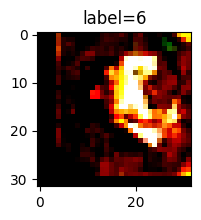

In [4]:
plt.figure(figsize=(2, 2))
plt.imshow(train_data[0][0].transpose(0, 2).numpy())
plt.title(f"label={train_data[0][1]}")

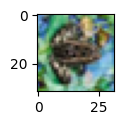

In [5]:
plt.figure(figsize=(1, 1))
plt.imshow(train_data.data[200])

# Dataloading


In [6]:
from torch.utils.data import DataLoader

dataloader = DataLoader(train_data, batch_size=100, shuffle=True)
for i, (x, y) in enumerate(dataloader):
    # x is the input
    # y is the target class
    if i == 0:
        print(f"x.shape: {x.shape}")
        print(f"y: {y}")
    break

x.shape: torch.Size([100, 3, 32, 32])
y: tensor([3, 7, 8, 1, 9, 9, 4, 4, 0, 9, 5, 8, 6, 9, 1, 7, 4, 2, 0, 2, 8, 1, 3, 8,
        2, 7, 8, 2, 5, 0, 0, 5, 1, 0, 7, 1, 3, 5, 1, 7, 3, 6, 3, 2, 3, 0, 1, 9,
        7, 1, 0, 3, 8, 2, 4, 8, 1, 8, 3, 4, 2, 9, 0, 1, 9, 7, 8, 4, 1, 7, 6, 5,
        2, 0, 5, 5, 2, 9, 7, 2, 8, 5, 1, 9, 2, 6, 1, 3, 1, 5, 3, 9, 0, 5, 3, 3,
        1, 2, 7, 7])


# Model

We use a slim ResNet18. Then standard ResNet18 is designed for 224x224 images, while CIFAR10 has 32x32 images.


In [7]:
# from https://github.com/weiaicunzai/pytorch-cifar100/blob/master/models/resnet.py

import torch
import torch.nn as nn


class BasicBlock(nn.Module):
    """Basic Block for resnet 18 and resnet 34"""

    # BasicBlock and BottleNeck block
    # have different output size
    # we use class attribute expansion
    # to distinct
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        # residual function
        self.residual_function = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                stride=stride,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels,
                out_channels * BasicBlock.expansion,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels * BasicBlock.expansion),
        )

        # shortcut
        self.shortcut = nn.Sequential()

        # the shortcut output dimension is not the same with residual function
        # use 1*1 convolution to match the dimension
        if stride != 1 or in_channels != BasicBlock.expansion * out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels * BasicBlock.expansion,
                    kernel_size=1,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(out_channels * BasicBlock.expansion),
            )

    def forward(self, x):
        return nn.ReLU(inplace=True)(self.residual_function(x) + self.shortcut(x))


class BottleNeck(nn.Module):
    """Residual block for resnet over 50 layers"""

    expansion = 4

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.residual_function = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels,
                out_channels,
                stride=stride,
                kernel_size=3,
                padding=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(
                out_channels,
                out_channels * BottleNeck.expansion,
                kernel_size=1,
                bias=False,
            ),
            nn.BatchNorm2d(out_channels * BottleNeck.expansion),
        )

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels * BottleNeck.expansion:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels * BottleNeck.expansion,
                    stride=stride,
                    kernel_size=1,
                    bias=False,
                ),
                nn.BatchNorm2d(out_channels * BottleNeck.expansion),
            )

    def forward(self, x):
        return nn.ReLU(inplace=True)(self.residual_function(x) + self.shortcut(x))


class ResNet(nn.Module):
    def __init__(self, block, num_block, num_classes=100):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
        )
        # we use a different inputsize than the original paper
        # so conv2_x's stride is 1
        self.conv2_x = self._make_layer(block, 64, num_block[0], 1)
        self.conv3_x = self._make_layer(block, 128, num_block[1], 2)
        self.conv4_x = self._make_layer(block, 256, num_block[2], 2)
        self.conv5_x = self._make_layer(block, 512, num_block[3], 2)
        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512 * block.expansion, num_classes)

    def _make_layer(self, block, out_channels, num_blocks, stride):
        """make resnet layers(by layer i didnt mean this 'layer' was the
        same as a neuron netowork layer, ex. conv layer), one layer may
        contain more than one residual block

        Args:
            block: block type, basic block or bottle neck block
            out_channels: output depth channel number of this layer
            num_blocks: how many blocks per layer
            stride: the stride of the first block of this layer

        Return:
            return a resnet layer
        """
        # we have num_block blocks per layer, the first block
        # could be 1 or 2, other blocks would always be 1
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(block(self.in_channels, out_channels, s))
            self.in_channels = out_channels * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x):
        output = self.conv1(x)
        output = self.conv2_x(output)
        output = self.conv3_x(output)
        output = self.conv4_x(output)
        output = self.conv5_x(output)
        output = self.avg_pool(output)
        output = output.view(output.size(0), -1)
        output = self.fc(output)
        return output


def resnet18(num_classes=100):
    """return a ResNet 18 object"""
    return ResNet(BasicBlock, [2, 2, 2, 2], num_classes=num_classes)


In [8]:
model = resnet18(num_classes=10)
print(model)

ResNet(
  (conv1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (conv2_x): Sequential(
    (0): BasicBlock(
      (residual_function): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (residual_function): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_

# Training


In [9]:
from tqdm import tqdm
from torch.utils.data import DataLoader

device = "cuda"  # set device='cuda' if you have a GPU
model = resnet18(num_classes=100)
model = model.to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.04)
criterion = torch.nn.CrossEntropyLoss()

# don't forget to set the training mode!
# it controls the behavior of modules that differ at training and inference time (e.g. BatchNorm)
model.train()

# Iterate over the dataset and train the model
for ep in range(10):
    # 10 epoch is a bit on the low end. With a GPU you can run a larger experiment
    # increase num_workers if you have more CPUs
    # setting num_workers > 0 allows to do the pre-processing in parallel.
    # with num_workers=0, the GPU is stuck waiting on the data that is preprocessed and augmented on the CPU
    dataloader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=0)
    pbar = tqdm(dataloader)
    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        # - reset the gradients
        optimizer.zero_grad()
        # - forward pass
        pred = model(x)
        loss = criterion(pred, y)
        # - backward pass
        loss.backward()
        # - descent step
        optimizer.step()
        pbar.set_description(f"Loss: {loss.item():0.4f}")


Loss: 1.2051: 100%|██████████| 1563/1563 [01:04<00:00, 24.24it/s]


# Evaluation


In [10]:
with torch.no_grad():
    model = model.eval()
    dataloader = DataLoader(
        test_data, batch_size=32, num_workers=0
    )  # increase num_workers if you have more CPUs
    pbar = tqdm(dataloader)
    correct, tot = 0, 0
    for x, y in pbar:
        x, y = x.to(device), y.to(device)
        pred = model(x)
        _, pred = torch.max(pred.data, 1)
        correct += (pred == y).sum().item()
        tot += x.shape[0]
        pbar.set_description(f"ACC: {correct / tot:.4f}")

ACC: 0.8483: 100%|██████████| 313/313 [00:05<00:00, 54.51it/s]


# Feature Maps


In [11]:
x.shape

torch.Size([16, 3, 32, 32])

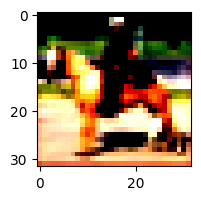

In [12]:
plt.figure(figsize=(2, 2))
plt.imshow(x[0].detach().cpu().numpy().transpose(1, 2, 0))

In [13]:
import numpy as np
from sklearn.decomposition import PCA


def visualize_pca(feature_map):
    """feature_map: torch.Tensor of shape (C, H, W) or (1, C, H, W)"""
    x = feature_map.detach().float().cpu().squeeze()
    C, H, W = x.shape
    x = x.reshape(C, -1).T.numpy()  # Reshape: (C, H, W) -> (H*W, C)
    x = PCA(n_components=3).fit_transform(x)  # PCA: C channels -> 3 components
    x = (x - x.min(axis=0)) / (np.ptp(x, axis=0) + 1e-8)  # Normalize in [0, 1]
    rgb = x.reshape(H, W, 3)  # Reshape to RGB image

    plt.figure(figsize=(3, 3))
    plt.imshow(rgb)
    return rgb


In [14]:
activations = []


def hook(model, input, output):
    activations.append(output.detach())


h = model.conv4_x.register_forward_hook(hook)
model(x)
h.remove()


In [15]:
activations[0].shape

torch.Size([16, 256, 8, 8])

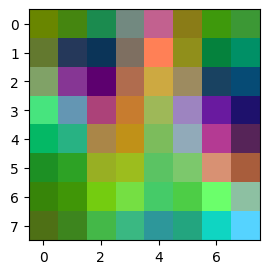

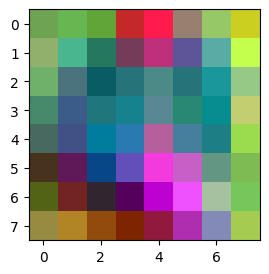

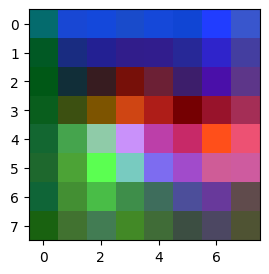

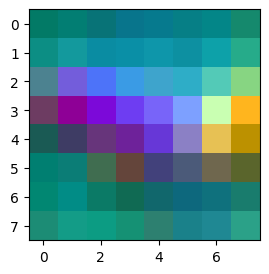

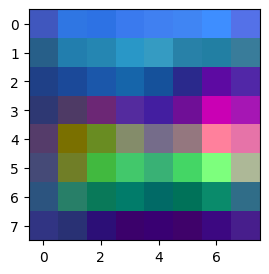

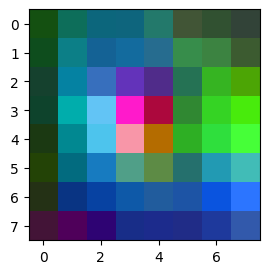

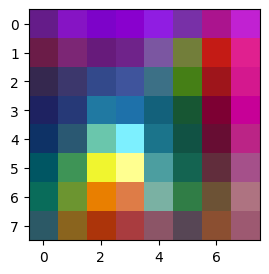

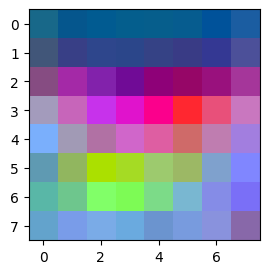

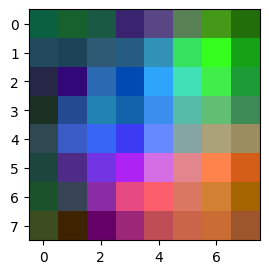

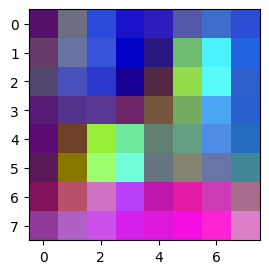

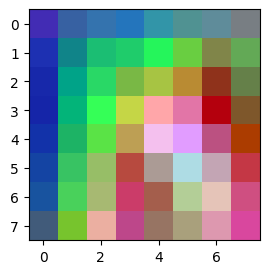

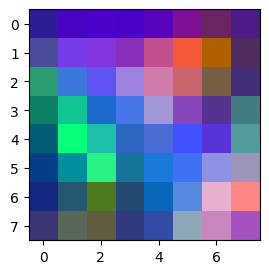

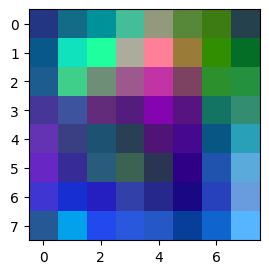

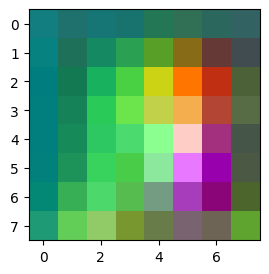

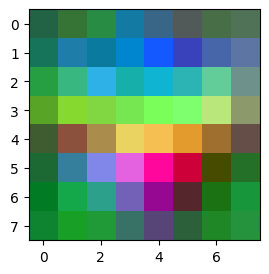

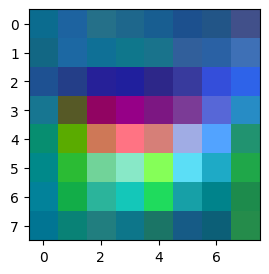

In [16]:
for iii in range(16):
    visualize_pca(activations[0][iii])

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

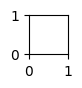

In [17]:
hx = activations[0][0]

for iii in range(64):
    plt.subplot(8, 8, iii + 1)
    plt.imshow(hx[iii])

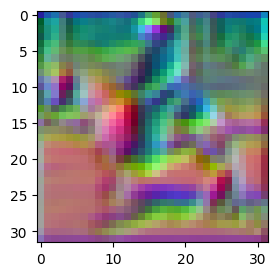

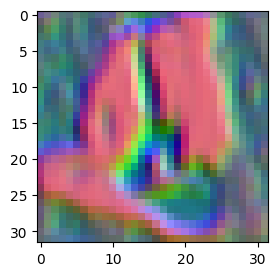

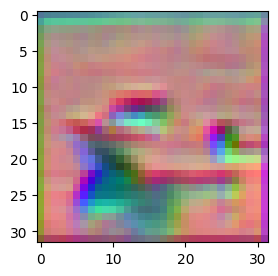

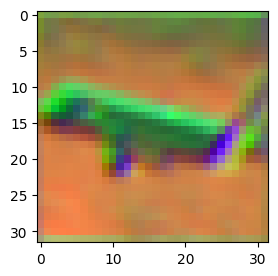

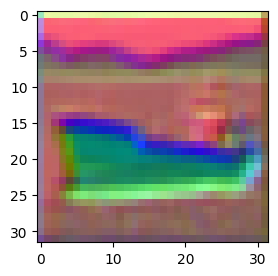

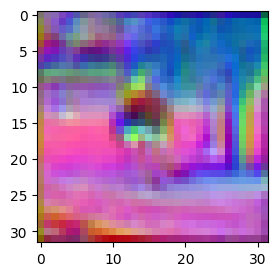

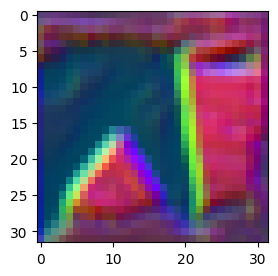

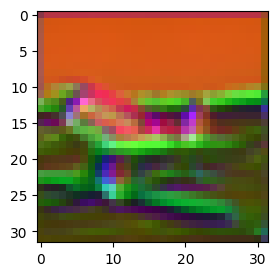

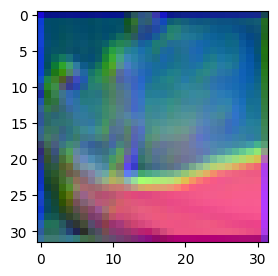

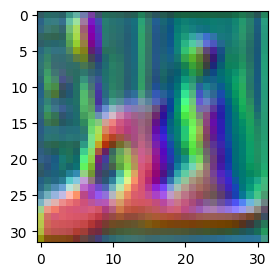

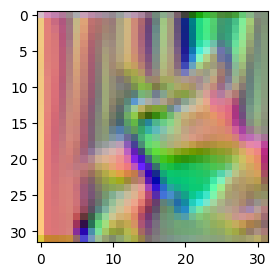

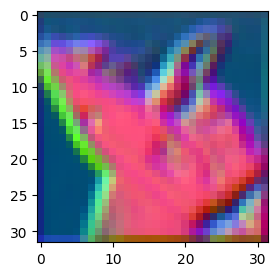

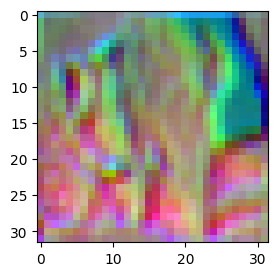

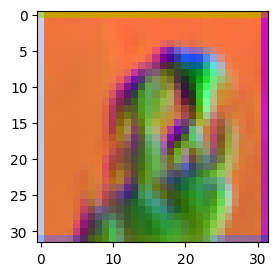

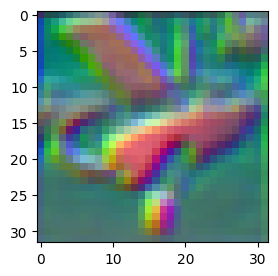

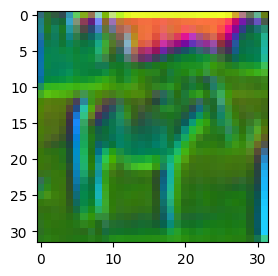

In [ ]:
activations = []


def hook(model, input, output):
    activations.append(output.detach())


h = model.conv1.register_forward_hook(hook)
model(x)
h.remove()

for iii in range(16):
    visualize_pca(activations[0][iii])

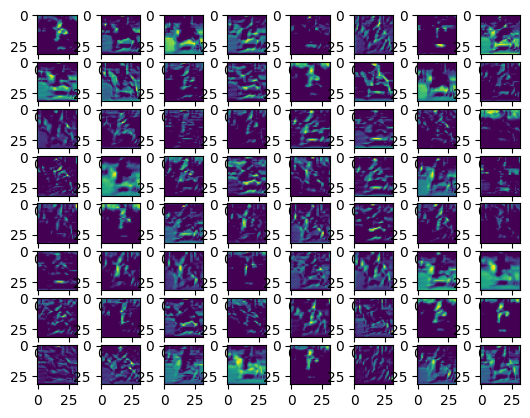

In [ ]:
hx = activations[0][0]

for iii in range(64):
    plt.subplot(8, 8, iii + 1)
    plt.imshow(hx[iii])

# Exercises

- **resnet**: check the ResNet code. Do you understand everything? If not, check the documentation or ask for help. Check that you understand the shapes of the feature maps and how the conv hyperparameters affect them.
- simple sanity checks:
  - **augmentations matter**: try to train a model with and without augmentations.
  - **training stability and lr**: try to increase the learning rate (10x, 100x, ...). What happens to the learning curve? You can also try some learning rate scheduler.
- **reproduce sota for CIFAR100**: use this notebook to reproduce a result from [this repo](https://github.com/weiaicunzai/pytorch-cifar100). NOTE: our resnet18 is slightly different from theirs (slim version, less units)
  - [learning rate scheduler in pytorch](https://docs.pytorch.org/docs/2.14/generated/torch.optim.lr_scheduler.MultiStepLR.html)
